## Replication: Howard (2026), main Excelsior Scholarship findings

### Step 1: Loading the cleaned panel 
I am starting with loading the panel I created during data cleaning (panel_clean.csv) 

In [1]:
import pandas as pd
panel=pd.read_csv("panel_clean.csv")

### Step 2: Checking My Sample Against Howard's
From the cleaned_panel, I'm only keeping the columns that I need to replicate the main findings of Howard (2026) 

In [2]:
columns_to_keep = [
    "unitid",
    "institution name",
    "fall_year",
    "state",
    "Grand total",
    "Number of full-time first-time undergraduates awarded Pell grants",
    "public",
    "Level of student",
    "Published in-state tuition and fees",
    "unemp_lag"
]

df = panel[columns_to_keep].copy()

df.head()

,unitid,institution name,fall_year,state,Grand total,Number of full-time first-time undergraduates awarded Pell grants,public,Level of student,Published in-state tuition and fees,unemp_lag
0,188438,SUNY Adirondack,2012,NY,740,372.0,True,"Full-time students, Undergraduate, Degree/cert...",3973.0,9.0
1,189547,SUNY Broome Community College,2012,NY,1357,768.0,True,"Full-time students, Undergraduate, Degree/cert...",4301.0,8.7
2,189839,Cayuga County Community College,2012,NY,651,451.0,True,"Full-time students, Undergraduate, Degree/cert...",4412.0,8.2
3,190053,Clinton Community College,2012,NY,422,267.0,True,"Full-time students, Undergraduate, Degree/cert...",4308.0,9.7
4,190169,Columbia-Greene Community College,2012,NY,348,200.0,True,"Full-time students, Undergraduate, Degree/cert...",4122.0,7.2


### Step 3: Checking the final dataset
Now that I've selected the columns I need, I'm checking the number of institutions in each state across the eight years (2012–2019).

In [3]:


df.groupby(["fall_year", "state"])["unitid"].nunique().unstack()

state,NY,PA
fall_year,,
2012,74,37
2013,74,37
2014,74,37
2015,74,37
2016,74,37
2017,74,37
2018,74,37
2019,74,37


As stated, in my data cleaning portion, Howard originally had 74 for NY schools per year, and 51 for PA schools per years. My PA numbers are off because he had additional Penn State campus data for their main campuses and satellite campuses. Specifically, in 2019 Penn State campuses began reporting to IPEDS under one name. Because I dont have granular Penn State data, I decided to drop Penn State from the current analysis. 

### Step 4: Creating the Treatment Variables

I'm creating treatment variables to identify which institutions were exposed to the Excelsior Scholarship. With New York as  the treatment group, while Pennsylvania serves as the control group.

Since Howard tests both 2017 and 2018 as the first year of treatment in his DiD models, I'm creating separate indicators for each year.

In [4]:


df["ny"] = (df["state"] == "NY").astype(int)



df["post_2017"] = (df["fall_year"] >= 2017).astype(int)



df["post_2018"] = (df["fall_year"] >= 2018).astype(int)



df["did_2017"] = df["ny"] * df["post_2017"]

df["did_2018"] = df["ny"] * df["post_2018"]


df.head()

,unitid,institution name,fall_year,state,Grand total,Number of full-time first-time undergraduates awarded Pell grants,public,Level of student,Published in-state tuition and fees,unemp_lag,ny,post_2017,post_2018,did_2017,did_2018
0,188438,SUNY Adirondack,2012,NY,740,372.0,True,"Full-time students, Undergraduate, Degree/cert...",3973.0,9.0,1,0,0,0,0
1,189547,SUNY Broome Community College,2012,NY,1357,768.0,True,"Full-time students, Undergraduate, Degree/cert...",4301.0,8.7,1,0,0,0,0
2,189839,Cayuga County Community College,2012,NY,651,451.0,True,"Full-time students, Undergraduate, Degree/cert...",4412.0,8.2,1,0,0,0,0
3,190053,Clinton Community College,2012,NY,422,267.0,True,"Full-time students, Undergraduate, Degree/cert...",4308.0,9.7,1,0,0,0,0
4,190169,Columbia-Greene Community College,2012,NY,348,200.0,True,"Full-time students, Undergraduate, Degree/cert...",4122.0,7.2,1,0,0,0,0


What I did here was create a binary indicator for four seperate columns.

    1. "ny": If an Institution is a NY instituion [Receives a 1 in the "ny" column if so, and a 0 if not
    2. "post_2017": An indicator for post treatment period 2017 (One of two treatment periods used by Howard)
    3. "post_2018": An indicator for post treatment period 2018 (One of two treatment periods used by Howard)
    4. "did_2017": Interaction term for Did models using 2017 as a treatment year
    5. "did_2018": Interaction term for Did models using 2018 as a treatment year

### Part 4: Checking Parallel Trends 

Before running the difference-in-differences analysis, I want to see whether New York and Pennsylvania followed similar enrollment trends before the Excelsior Scholarship was introduced in 2017.

I'm looking at the average enrollment per institution for:
1. All First-time, full-time undergraduates
2. First-time, full-time undergraduate Pell Grant recipients.

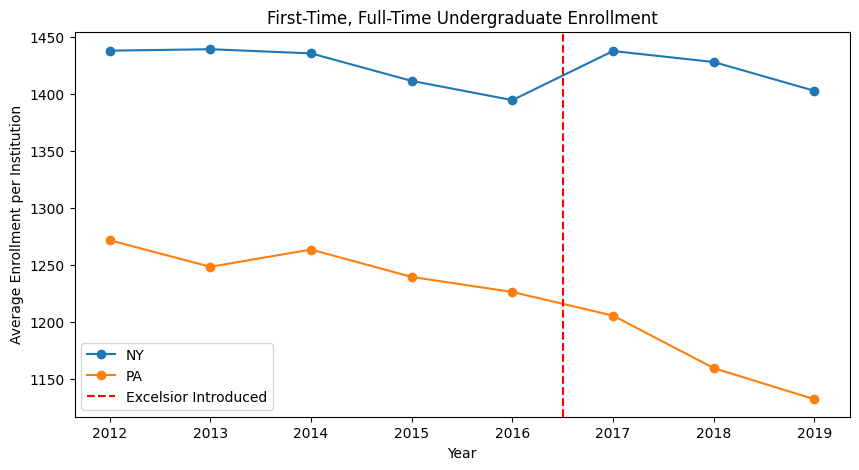

In [5]:
import matplotlib.pyplot as plt



ftft_trends = (
    df.groupby(["fall_year", "state"])["Grand total"]
    .mean()
    .unstack()
)



ftft_trends.plot(
    figsize=(10, 5),
    marker="o"
)

plt.axvline(
    x=2016.5,
    color="red",
    linestyle="--",
    label="Excelsior Introduced"
)

plt.title("First-Time, Full-Time Undergraduate Enrollment")
plt.xlabel("Year")
plt.ylabel("Average Enrollment per Institution")
plt.xticks(range(2012, 2020))
plt.legend()
plt.show()

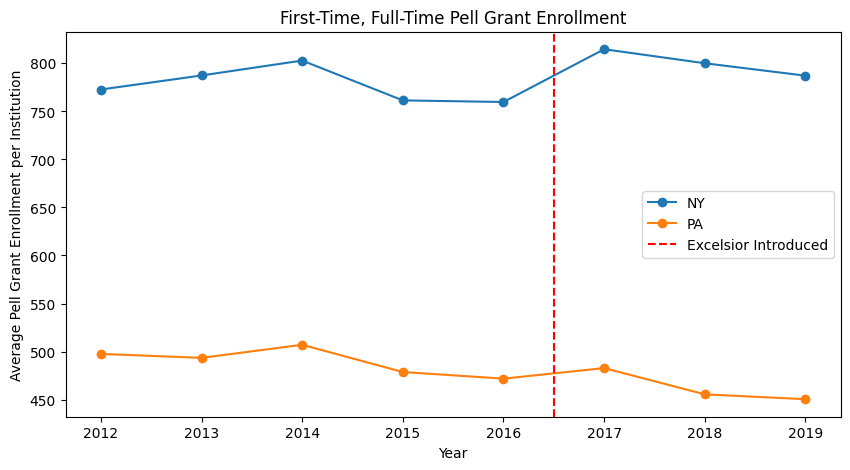

In [6]:

pell_trends = (
    df.groupby(["fall_year", "state"])[
        "Number of full-time first-time undergraduates awarded Pell grants"
    ]
    .mean()
    .unstack()
)



pell_trends.plot(
    figsize=(10, 5),
    marker="o"
)

plt.axvline(
    x=2016.5,
    color="red",
    linestyle="--",
    label="Excelsior Introduced"
)

plt.title("First-Time, Full-Time Pell Grant Enrollment")
plt.xlabel("Year")
plt.ylabel("Average Pell Grant Enrollment per Institution")
plt.xticks(range(2012, 2020))
plt.legend()
plt.show()

In [7]:
## Checking which Pennsylvania institutions experienced
## the largest Pell Grant enrollment declines between 2018 and 2019

pell_col = "Number of full-time first-time undergraduates awarded Pell grants"

pa_pell = df[df["state"] == "PA"].copy()

pa_change = pa_pell.pivot(
    index=["unitid", "institution name"],
    columns="fall_year",
    values=pell_col
)

pa_change["change"] = pa_change[2019] - pa_change[2018]

display(
    pa_change[[2018, 2019, "change"]]
    .sort_values("change")
    .head(10)
)

,fall_year,2018,2019,change
unitid,institution name,,,
213349,Kutztown University of Pennsylvania,619.0,496.0,-123.0
216339,Temple University,1437.0,1327.0,-110.0
213020,Indiana University of Pennsylvania,932.0,843.0,-89.0
210605,Community College of Allegheny County,955.0,876.0,-79.0
212115,East Stroudsburg University of Pennsylvania,579.0,509.0,-70.0
216825,Westmoreland County Community College,305.0,236.0,-69.0
211927,Delaware County Community College,359.0,290.0,-69.0
213598,Lincoln University,381.0,318.0,-63.0
211361,California University of Pennsylvania,480.0,435.0,-45.0


After visually examining the enrollment trends, I'm conducting a statistical test to determine whether New York and Pennsylvania had significantly different enrollment trends before the introduction of the Excelsior Scholarship.

Following Howard's approach in Tables 7 and 8, I'm using a Wald F-test to assess whether the difference in pretreatment slopes is statistically significant.

Since Howard tests both 2017 and 2018 as the beginning of treatment, I'm testing both periods for first-time, full-time undergraduate enrollment and Pell Grant enrollment.

## Step 5: Statistical Analysis of Parallel Trends

In [8]:
import statsmodels.formula.api as smf
import pandas as pd

## Identifying the two enrollment outcomes

outcomes = {
    "FTFT Enrollment": "Grand total",
    "Pell FTFT Enrollment": "Number of full-time first-time undergraduates awarded Pell grants"
}

results = []

## Testing parallel trends using 2017 and 2018 as treatment years

for treatment_year in [2017, 2018]:

    for label, outcome in outcomes.items():

        ## Keeping only observations before treatment

        pre = df[df["fall_year"] < treatment_year].copy()

        pre = pre.dropna(subset=[outcome])

        pre["time"] = pre["fall_year"] - 2012

        ## Estimating the difference in slopes between NY and PA

        model = smf.ols(
            f'Q("{outcome}") ~ C(unitid) + C(fall_year) + ny:time',
            data=pre
        ).fit(
            cov_type="cluster",
            cov_kwds={"groups": pre["unitid"]}
        )

        ## Testing whether the difference in slopes equals zero

        test = model.f_test("ny:time = 0")

        results.append({
            "Outcome": label,
            "Treatment Year": treatment_year,
            "Slope Difference": model.params["ny:time"],
            "F-statistic": float(test.fvalue),
            "p-value": float(test.pvalue)
        })

parallel_results = pd.DataFrame(results)

display(parallel_results.round(3))

,Outcome,Treatment Year,Slope Difference,F-statistic,p-value
0,FTFT Enrollment,2017,-1.481,0.008,0.931
1,Pell FTFT Enrollment,2017,1.426,0.025,0.874
2,FTFT Enrollment,2018,7.449,0.258,0.612
3,Pell FTFT Enrollment,2018,7.212,0.858,0.356


None of the p-values from the pretreatment trend tests are statistically significant (p > 0.05). Therefore, we fail to reject the null hypothesis that the pretreatment slopes are equal across New York and Pennsylvania. This provides some support for the parallel trends assumption.

## Step 6: Initial Diff in Diff Analysis

In [9]:
import statsmodels.formula.api as smf
import pandas as pd



outcomes = {
    "FTFT Enrollment": "Grand total",
    "Pell FTFT Enrollment": "Number of full-time first-time undergraduates awarded Pell grants"
}

did_results = []



for year in [2017, 2018]:

    treatment = f"did_{year}"

    for label, outcome in outcomes.items():

        data = df.dropna(subset=[outcome]).copy()

        model = smf.ols(
            f'Q("{outcome}") ~ {treatment} + C(unitid) + C(fall_year)',
            data=data
        ).fit(
            cov_type="cluster",
            cov_kwds={"groups": data["unitid"]}
        )

        did_results.append({
            "Outcome": label,
            "Treatment Year": year,
            "Coefficient": model.params[treatment],
            "Standard Error": model.bse[treatment],
            "p-value": model.pvalues[treatment]
        })

did_results = pd.DataFrame(did_results)

display(did_results.round(3))

,Outcome,Treatment Year,Coefficient,Standard Error,p-value
0,FTFT Enrollment,2017,82.994,49.341,0.093
1,Pell FTFT Enrollment,2017,50.639,27.613,0.067
2,FTFT Enrollment,2018,85.777,49.759,0.085
3,Pell FTFT Enrollment,2018,46.106,28.047,0.100


In [12]:
import numpy as np



df["tuition"] = pd.to_numeric(
    df["Published in-state tuition and fees"],
    errors="coerce"
)

df["unemp_lag"] = pd.to_numeric(
    df["unemp_lag"],
    errors="coerce"
)



df["ln_tuition"] = np.log(
    df["tuition"].where(df["tuition"] > 0)
)

df[["tuition", "ln_tuition", "unemp_lag"]].describe()

,tuition,ln_tuition,unemp_lag
count,888.000000,888.000000,888.000000
mean,7602.908784,8.878673,6.306532
std,2719.436694,0.334855,1.807782
min,3520.000000,8.166216,3.300000
25%,5265.250000,8.568884,4.800000
50%,7348.500000,8.902251,6.000000
75%,8876.500000,9.091162,7.600000
max,19718.000000,9.889287,12.600000


I'm using published in-state tuition as my measure. Howard specifies logged tuition but does not clearly identify the exact tuition measure, so this remains one possible difference between my replication and his analysis.

In [13]:


outcomes = {
    "FTFT Enrollment": "Grand total",
    "Pell FTFT Enrollment": "Number of full-time first-time undergraduates awarded Pell grants"
}

adjusted_results = []



for year in [2017, 2018]:

    treatment = f"did_{year}"

    for label, outcome in outcomes.items():

        data = df.dropna(
            subset=[outcome, "ln_tuition", "unemp_lag"]
        ).copy()

        model = smf.ols(
            f'Q("{outcome}") ~ {treatment} + ln_tuition + unemp_lag + C(unitid) + C(fall_year)',
            data=data
        ).fit(
            cov_type="cluster",
            cov_kwds={"groups": data["unitid"]}
        )

        adjusted_results.append({
            "Outcome": label,
            "Treatment Year": year,
            "Coefficient": model.params[treatment],
            "Standard Error": model.bse[treatment],
            "p-value": model.pvalues[treatment],
            "Observations": int(model.nobs)
        })

adjusted_results = pd.DataFrame(adjusted_results)

display(adjusted_results.round(3))

,Outcome,Treatment Year,Coefficient,Standard Error,p-value,Observations
0,FTFT Enrollment,2017,38.262,50.009,0.444,888
1,Pell FTFT Enrollment,2017,27.137,27.248,0.319,888
2,FTFT Enrollment,2018,58.327,45.115,0.196,888
3,Pell FTFT Enrollment,2018,30.300,25.678,0.238,888


In [14]:
## Comparing the treatment coefficients across models

comparison = did_results.merge(
    adjusted_results,
    on=["Outcome", "Treatment Year"],
    suffixes=("_without", "_with")
)

display(
    comparison[
        [
            "Outcome",
            "Treatment Year",
            "Coefficient_without",
            "Coefficient_with",
            "p-value_without",
            "p-value_with",
            "Observations"
        ]
    ].round(3)
)

,Outcome,Treatment Year,Coefficient_without,Coefficient_with,p-value_without,p-value_with,Observations
0,FTFT Enrollment,2017,82.994,38.262,0.093,0.444,888
1,Pell FTFT Enrollment,2017,50.639,27.137,0.067,0.319,888
2,FTFT Enrollment,2018,85.777,58.327,0.085,0.196,888
3,Pell FTFT Enrollment,2018,46.106,30.300,0.100,0.238,888


## 8. Estimating the Event Study

In [15]:
## Creating the event-study indicators

event_years = [2012, 2013, 2014, 2015, 2017, 2018, 2019]

for year in event_years:

    df[f"ny_{year}"] = (
        (df["state"] == "NY") &
        (df["fall_year"] == year)
    ).astype(int)

In [16]:
## Identifying the enrollment outcomes

outcomes = {
    "FTFT Enrollment": "Grand total",
    "Pell FTFT Enrollment": "Number of full-time first-time undergraduates awarded Pell grants"
}

event_results = []
event_models = {}

## Creating the event-study regression terms

event_terms = " + ".join(
    [f"ny_{year}" for year in event_years]
)

## Running the event-study models

for label, outcome in outcomes.items():

    data = df.dropna(subset=[outcome]).copy()

    model = smf.ols(
        f'Q("{outcome}") ~ {event_terms} + C(unitid) + C(fall_year)',
        data=data
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": data["unitid"]}
    )

    event_models[label] = model

    for year in event_years:

        term = f"ny_{year}"

        event_results.append({
            "Outcome": label,
            "Year": year,
            "Coefficient": model.params[term],
            "Standard Error": model.bse[term],
            "p-value": model.pvalues[term],
            "CI Lower": model.conf_int().loc[term, 0],
            "CI Upper": model.conf_int().loc[term, 1]
        })

event_results = pd.DataFrame(event_results)

display(
    event_results.round(3)
)

,Outcome,Year,Coefficient,Standard Error,p-value,CI Lower,CI Upper
0,FTFT Enrollment,2012,-2.027,63.202,0.974,-125.901,121.846
1,FTFT Enrollment,2013,22.514,53.949,0.676,-83.225,128.252
2,FTFT Enrollment,2014,3.757,39.041,0.923,-72.763,80.276
3,FTFT Enrollment,2015,3.649,23.976,0.879,-43.344,50.641
4,FTFT Enrollment,2017,63.649,22.323,0.004,19.896,107.402
5,FTFT Enrollment,2018,100.014,32.807,0.002,35.713,164.314
6,FTFT Enrollment,2019,102.054,42.892,0.017,17.987,186.121
7,Pell FTFT Enrollment,2012,-12.730,32.952,0.699,-77.314,51.854
8,Pell FTFT Enrollment,2013,6.000,27.430,0.827,-47.761,59.761
9,Pell FTFT Enrollment,2014,7.905,23.851,0.740,-38.841,54.652


The event-study estimates suggest increases in first-time, full-time undergraduate enrollment at New York public institutions following the introduction of the Excelsior Scholarship. Using 2016 as the reference year, the estimated enrollment increases were approximately 64, 100, and 102 students per institution in 2017, 2018, and 2019, respectively. All three coefficients were statistically significant at the 5% level.

Similar findings were observed among Pell Grant recipients, with estimated increases of approximately 44, 57, and 49 students per institution across the three post-treatment years. The coefficients were statistically significant at the 5% level in 2017 and 2018, while the 2019 estimate was marginally significant at the 10% level. None of the individual pretreatment coefficients were statistically significant.

Overall, these findings are generally consistent with Howard's results, although differences in the institutional sample may explain some variation in the estimated coefficients.